# Практична робота №5
**Статистична обробка результатів експерименту з превентивної верифікації ML-експериментів**

Notebook аналізує результати практичної №4: 30 парних вимірювань latency, якість виявлення методологічно невалідних специфікацій та порівняння трьох конфігурацій валідатора.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import shapiro, wilcoxon, friedmanchisquare, rankdata, studentized_range
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score
from pathlib import Path
DATA=Path('.')

## 1. Завантаження 30 експериментальних прогонів

In [2]:
lat=pd.read_csv(DATA/'pr5_latency_30runs.csv')
lat.describe()

,run,Baseline (local),Full validator
count,30.000000,30.000000,30.000000
mean,15.500000,4.514972,4.933394
std,8.803408,0.131156,0.238717
min,1.000000,4.333521,4.635938
25%,8.250000,4.422644,4.788643
50%,15.500000,4.495924,4.877656
75%,22.750000,4.584614,4.998475
max,30.000000,4.974649,5.784948


## 2. Тест Шапіро-Уїлка

In [3]:
for c in ['Baseline (local)','Full validator']:
    s,p=shapiro(lat[c])
    print(c, 'W=',round(s,4),'p=',p)
diff=lat['Full validator']-lat['Baseline (local)']
print('paired differences:', shapiro(diff))

Baseline (local) W= 0.8955 p= 0.006537513891239233
Full validator W= 0.8363 p= 0.0003246197834749501
paired differences: ShapiroResult(statistic=np.float64(0.8506697769695392), pvalue=np.float64(0.0006403982557869377))


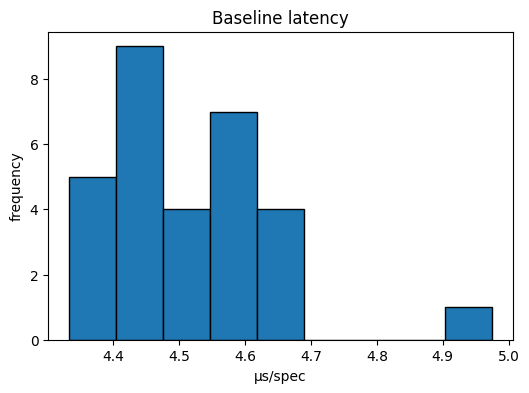

In [4]:
fig,ax=plt.subplots(figsize=(6,4)); ax.hist(lat['Baseline (local)'],bins=9,edgecolor='black'); ax.set_title('Baseline latency'); ax.set_xlabel('μs/spec'); ax.set_ylabel('frequency'); plt.show()

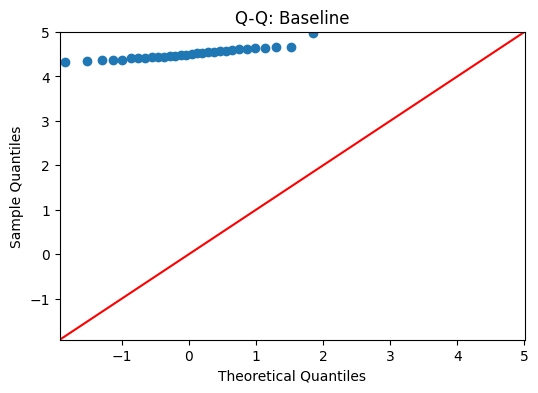

In [5]:
fig=plt.figure(figsize=(6,4)); ax=fig.add_subplot(111); sm.qqplot(lat['Baseline (local)'],line='45',ax=ax); ax.set_title('Q-Q: Baseline'); plt.show()

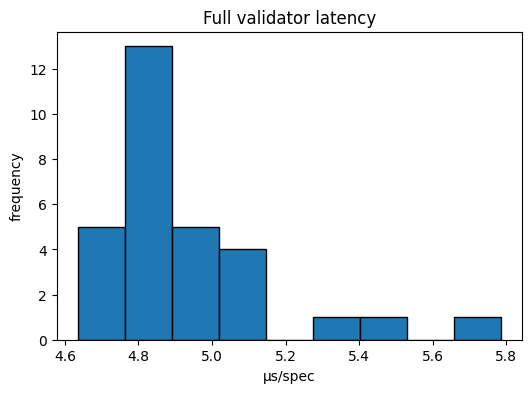

In [6]:
fig,ax=plt.subplots(figsize=(6,4)); ax.hist(lat['Full validator'],bins=9,edgecolor='black'); ax.set_title('Full validator latency'); ax.set_xlabel('μs/spec'); ax.set_ylabel('frequency'); plt.show()

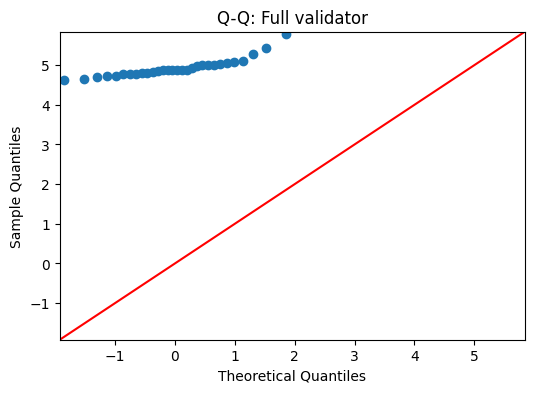

In [7]:
fig=plt.figure(figsize=(6,4)); ax=fig.add_subplot(111); sm.qqplot(lat['Full validator'],line='45',ax=ax); ax.set_title('Q-Q: Full validator'); plt.show()

## 3. Парне статистичне порівняння

In [8]:
res_w=wilcoxon(lat['Full validator'],lat['Baseline (local)'])
print(res_w)
print('Median baseline:',lat['Baseline (local)'].median())
print('Median full:',lat['Full validator'].median())

WilcoxonResult(statistic=np.float64(1.0), pvalue=np.float64(3.725290298461914e-09))
Median baseline: 4.495924448529411
Median full: 4.877656495098039


/tmp/ipykernel_940/1987093920.py:1: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  fig,ax=plt.subplots(figsize=(6,4)); ax.boxplot([lat['Baseline (local)'],lat['Full validator']],labels=['Baseline','Full']); ax.set_ylabel('μs/spec'); ax.set_title('Latency (30 paired runs)'); plt.show()


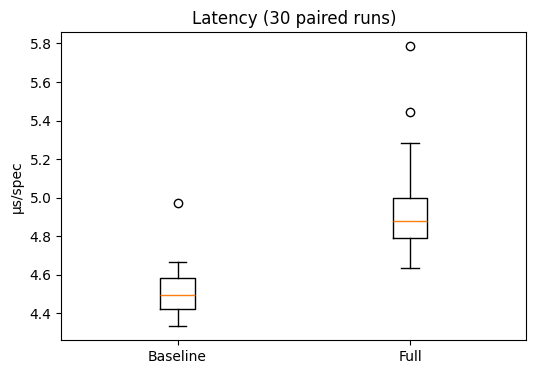

In [9]:
fig,ax=plt.subplots(figsize=(6,4)); ax.boxplot([lat['Baseline (local)'],lat['Full validator']],labels=['Baseline','Full']); ax.set_ylabel('μs/spec'); ax.set_title('Latency (30 paired runs)'); plt.show()

## 4. Метрики виявлення невалідних ML-експериментів

In [10]:
m=pd.read_csv(DATA/'pr5_classification_metrics.csv'); m

,configuration,TN,FP,FN,TP,accuracy,precision,recall,f1,roc_auc
0,Baseline (local),8,0,52,8,0.235294,1.0,0.133333,0.235294,0.566667
1,Full validator,8,0,0,60,1.000000,1.0,1.000000,1.000000,1.000000
2,Ablation - provenance,8,0,29,31,0.573529,1.0,0.516667,0.681319,0.758333


ROC-AUC обчислено за числом виявлених порушень як скоринговою функцією. Для повного валідатора на контрольованому benchmark усі 8 типів порушень мають відповідне правило, тому AUC=1.0.

## 5. Три алгоритми × п’ять benchmark-наборів × 10 повторів

In [11]:
r=pd.read_csv(DATA/'pr5_three_algorithms_5datasets.csv')
p=r.pivot(index=['dataset','run'],columns='algorithm',values='f1')
p.head()

algorithm                      Ablation - provenance  ...  Full validator
dataset                   run                         ...                
Dataset 1 - preprocessing 1                      0.0  ...             1.0
                          2                      0.0  ...             1.0
                          3                      0.0  ...             1.0
                          4                      0.0  ...             1.0
                          5                      0.0  ...             1.0

[5 rows x 3 columns]

In [12]:
alg=['Baseline (local)','Full validator','Ablation - provenance']
fr=friedmanchisquare(*[p[a] for a in alg]); print('Friedman:',fr)
ranks=np.vstack([rankdata(-row[alg].to_numpy(),method='average') for _,row in p.iterrows()])
avg=ranks.mean(axis=0); print(dict(zip(alg,avg)))

Friedman: FriedmanchisquareResult(statistic=np.float64(80.0), pvalue=np.float64(4.248354255291595e-18))
{'Baseline (local)': np.float64(2.8), 'Full validator': np.float64(1.2), 'Ablation - provenance': np.float64(2.0)}


## 6. Nemenyi post-hoc

In [13]:
import math
N=len(p); k=len(alg); se=math.sqrt(k*(k+1)/(6*N))
for i in range(k):
    for j in range(i+1,k):
        q=abs(avg[i]-avg[j])/se
        pv=studentized_range.sf(q*math.sqrt(2),k,np.inf)
        print(alg[i], 'vs', alg[j], 'p=',pv)

Baseline (local) vs Full validator p= 3.6637359812630166e-15
Baseline (local) vs Ablation - provenance p= 0.00018710512242481325
Full validator vs Ablation - provenance p= 0.00018710512242481325


## 7. Cohen's dz

In [14]:
def dz(a,b):
    d=np.asarray(a)-np.asarray(b); return d.mean()/d.std(ddof=1)
for i in range(k):
    for j in range(i+1,k):
        print(alg[i], 'vs', alg[j], dz(p[alg[i]],p[alg[j]]))

Baseline (local) vs Full validator -3.217335854398791
Baseline (local) vs Ablation - provenance -1.0186496251525985
Full validator vs Ablation - provenance 1.0217206288796665


## Висновок
На контрольованому benchmark повний валідатор забезпечує найвищу повноту та F1, але має статистично значуще збільшення latency відносно локального baseline. Тест Фрідмана та post-hoc Nemenyi підтверджують систематичні відмінності між трьома конфігураціями. Висновки стосуються саме синтетичного benchmark специфікацій із практичної №4 і не є доказом узагальнення на реальні ML-проєкти.